In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from sklearn import linear_model,metrics,preprocessing

In [ ]:
train=np.loadtxt("q5_train.csv",skiprows=1,delimiter=",")
test=np.loadtxt("q5_test.csv",skiprows=1,delimiter=",")
X_train, y_train = train[:, :-1], train[:, -1]
X_test = test[:, :]

In [ ]:
std=preprocessing.RobustScaler()
std.fit(X_train)
std_X_train=std.transform(X_train)
std_X_test=std.transform(X_test)

x = std_X_train[:, 7]
median = np.median(x)
mad = np.median(np.abs(x - median))
mask = np.abs(x - median) <= 3 * mad

X_train_clean = std_X_train[mask]
y_train_clean = y_train[mask]
train_clean = train[mask]

print(X_train_clean.shape, X_train.shape)

(222, 8) (240, 8)


# Corr Coeff

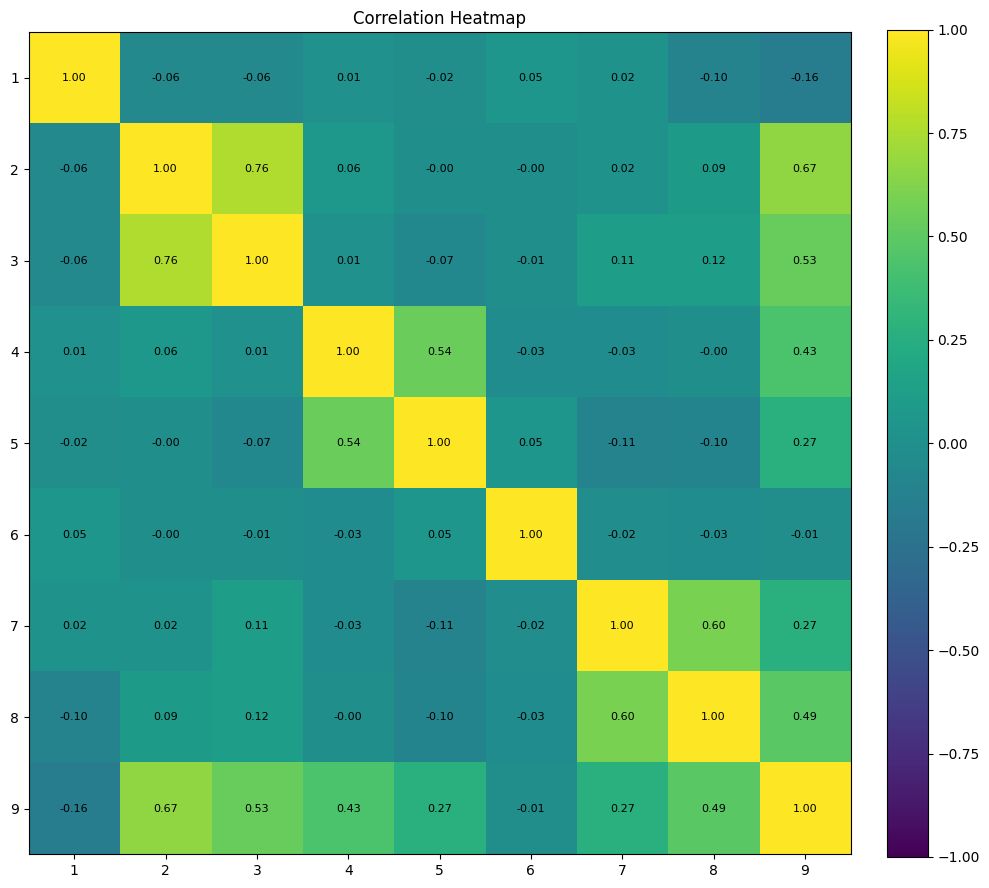

In [ ]:
corr = np.corrcoef(train_clean, rowvar=False)

n = corr.shape[0]
labels = np.arange(1, n + 1)

plt.figure(figsize=(10, 10))
im = plt.imshow(corr, vmin=-1, vmax=1)

plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(np.arange(n), labels)
plt.yticks(np.arange(n), labels)

# annotate values
for i in range(n):
    for j in range(n):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=8)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Scatter plot

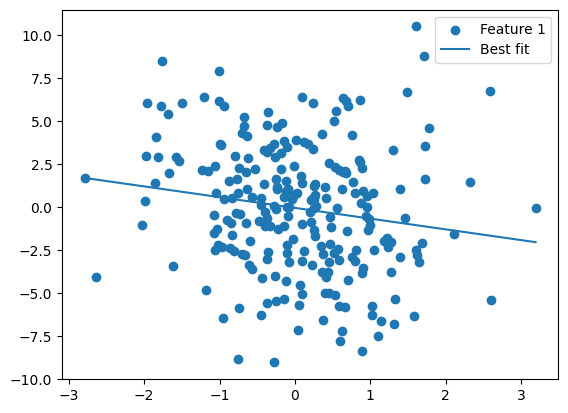

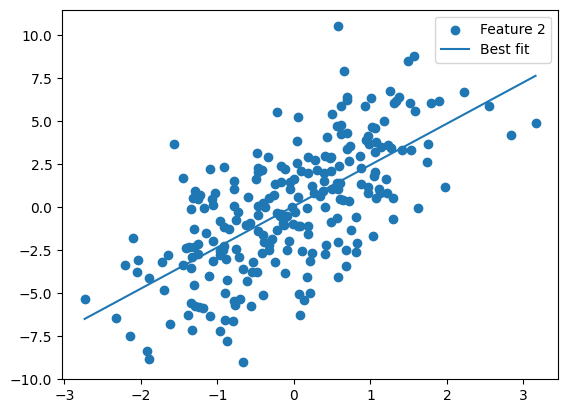

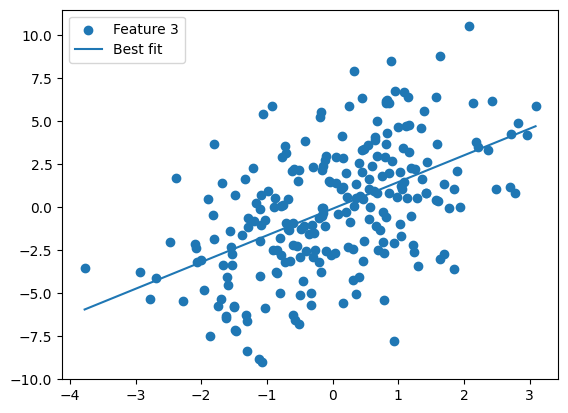

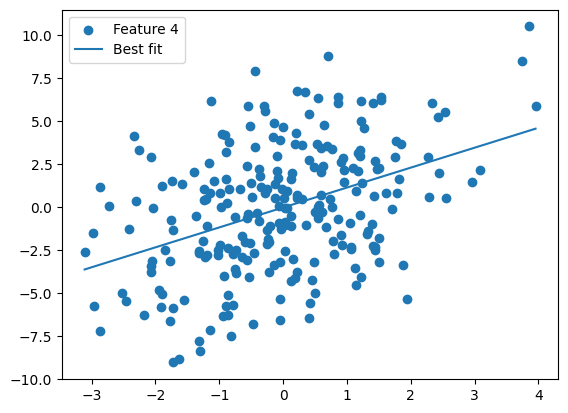

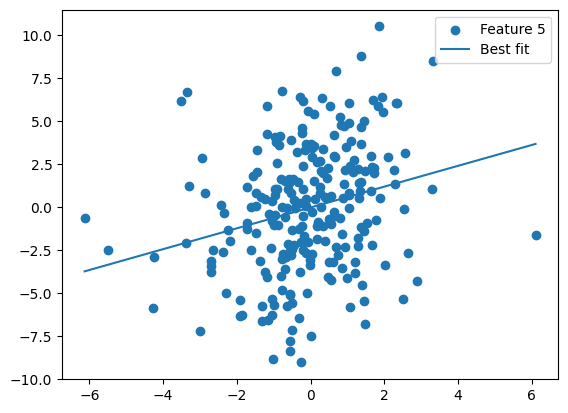

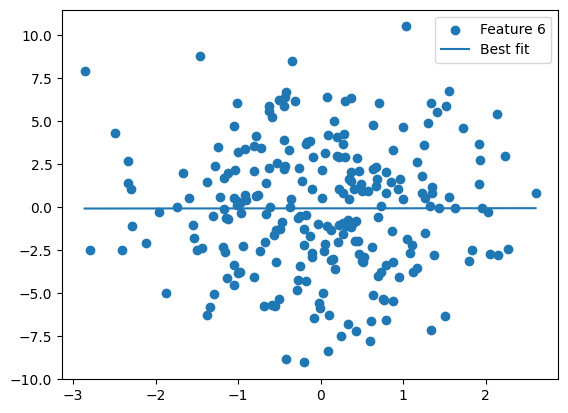

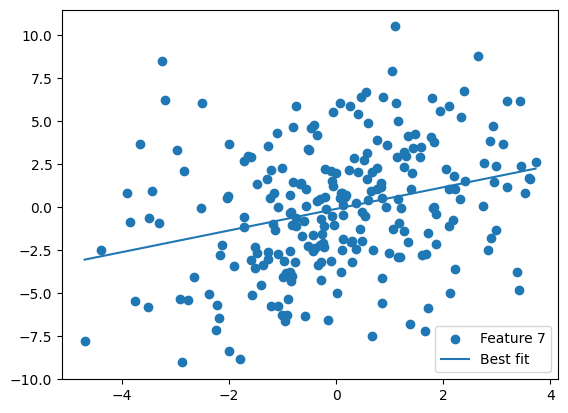

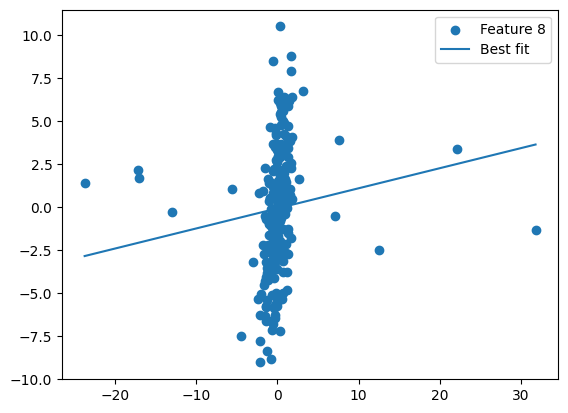

In [ ]:
for i in range(X_train.shape[1]):
    x = X_train[:, i]
    plt.figure()
    plt.scatter(x, y_train, label=f'Feature {i+1}')
    plt.plot(np.sort(x), np.polyval(np.polyfit(x, y_train, 1), np.sort(x)), label='Best fit')
    plt.legend()
    plt.show()

# Normal

[-0.58666043  2.20585518  0.07311211  0.92317255  0.2841504   0.0256194
  0.65040532  0.06284771]
8


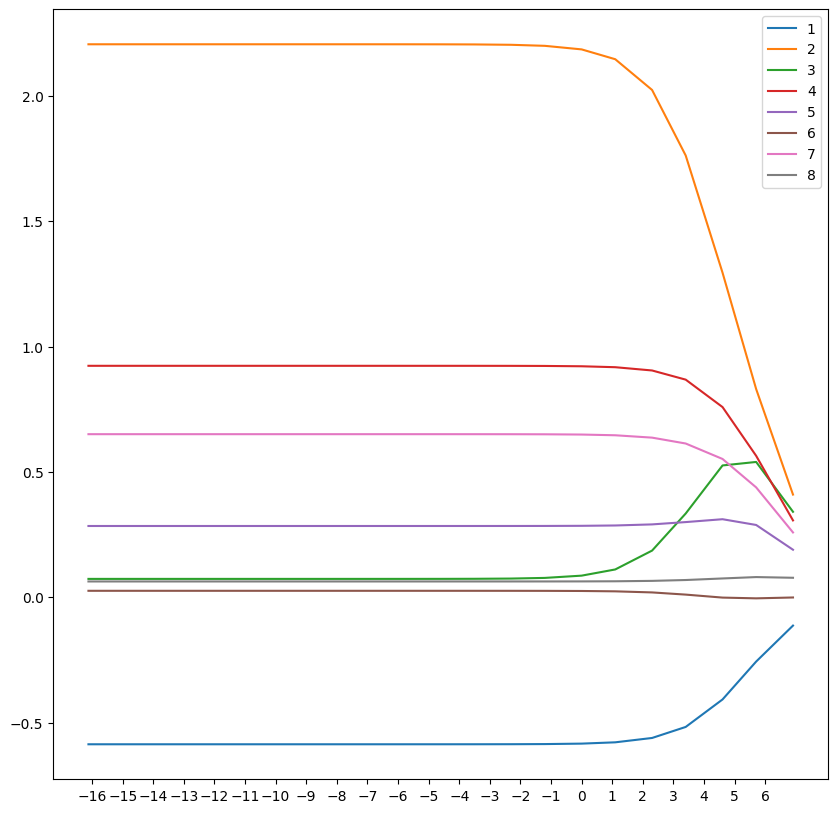

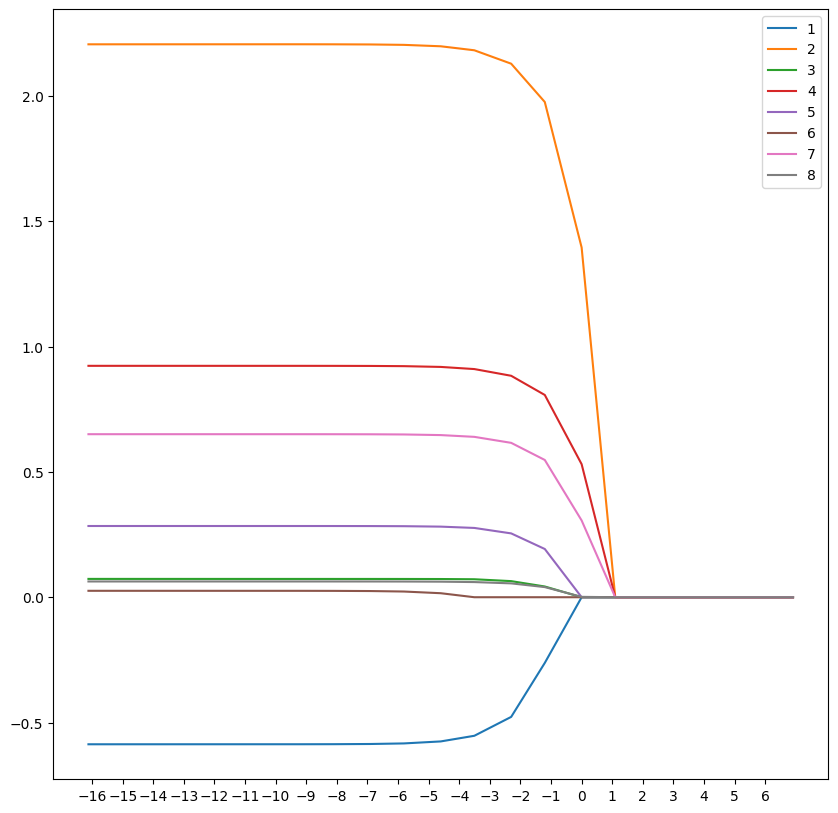

In [ ]:
alphas = [1e-7, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1, 3, 10, 30, 100, 300, 1000]
log_al=np.log(np.array(alphas))
reg=linear_model.LinearRegression()
reg.fit(X_train,y_train)
print(reg.coef_)

features=reg.coef_.size
print(features)
coeffs=[]
for i in alphas:
    ridge=linear_model.Ridge(alpha=i)
    ridge.fit(X_train,y_train)
    coeffs.append(ridge.coef_)

coeffs=np.array(coeffs)

plt.figure(figsize=(10,10))
for i in range(features):
    plt.plot(log_al,coeffs[:,i],label=i+1)
plt.xticks(np.arange(int(log_al.min()), int(log_al.max()) + 1))
plt.legend()
plt.show()

coeffs=[]
for i in alphas:
    lasso=linear_model.Lasso(alpha=i)
    lasso.fit(X_train,y_train)
    coeffs.append(lasso.coef_)

coeffs=np.array(coeffs)

plt.figure(figsize=(10,10))
for i in range(features):
    plt.plot(log_al,coeffs[:,i],label=i+1)
plt.xticks(np.arange(int(log_al.min()), int(log_al.max()) + 1))
plt.legend()
plt.show()


# Standardised

[-0.75628447  3.38927065  0.12550369  1.63148444  0.52543588  0.03542887
  1.44837967  0.08827866]
8


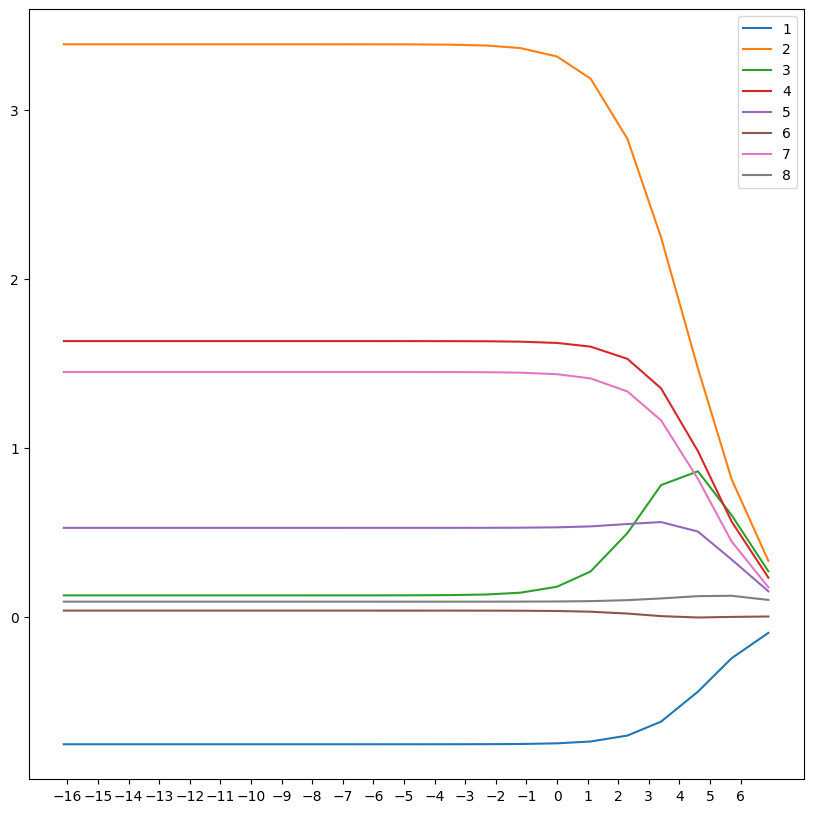

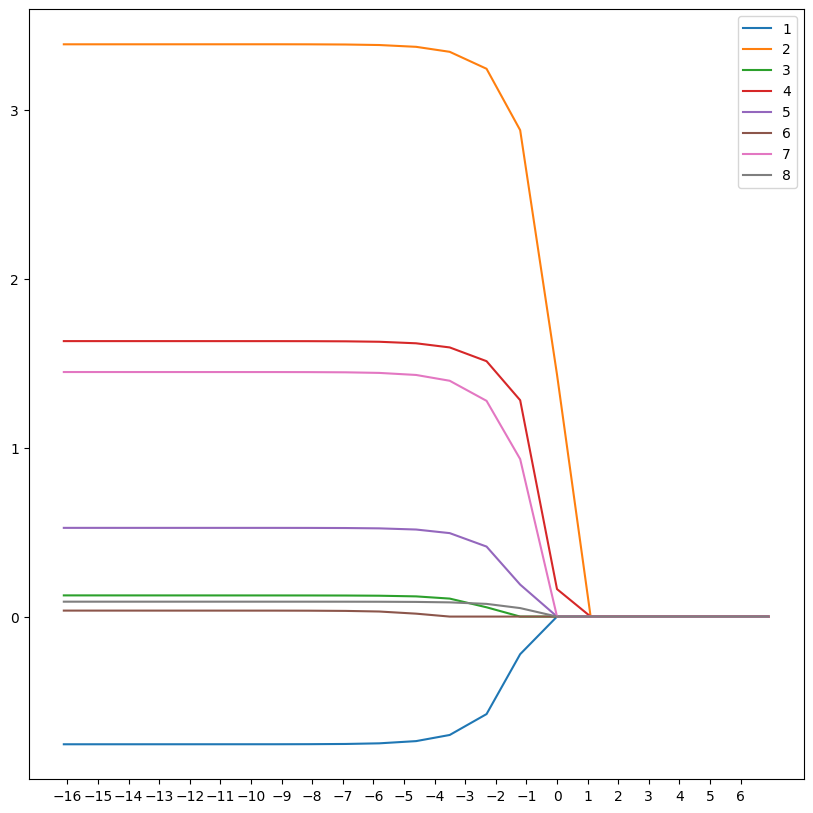

In [ ]:
alphas = [1e-7, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1, 3, 10, 30, 100, 300, 1000]
log_al=np.log(np.array(alphas))
reg=linear_model.LinearRegression()
reg.fit(std_X_train,y_train)
print(reg.coef_)

features=reg.coef_.size
print(features)
coeffs=[]
for i in alphas:
    ridge=linear_model.Ridge(alpha=i)
    ridge.fit(std_X_train,y_train)
    coeffs.append(ridge.coef_)

coeffs=np.array(coeffs)

plt.figure(figsize=(10,10))
for i in range(features):
    plt.plot(log_al,coeffs[:,i],label=i+1)
plt.xticks(np.arange(int(log_al.min()), int(log_al.max()) + 1))
plt.legend()
plt.show()

coeffs=[]
for i in alphas:
    lasso=linear_model.Lasso(alpha=i)
    lasso.fit(std_X_train,y_train)
    coeffs.append(lasso.coef_)

coeffs=np.array(coeffs)

plt.figure(figsize=(10,10))
for i in range(features):
    plt.plot(log_al,coeffs[:,i],label=i+1)
plt.xticks(np.arange(int(log_al.min()), int(log_al.max()) + 1))
plt.legend()
plt.show()


# Outliers Removed (after standardising)

[-0.41823407  3.14183177  0.22711295  1.58548327  0.62789083  0.04975369
  0.09436434  2.52935877]
8


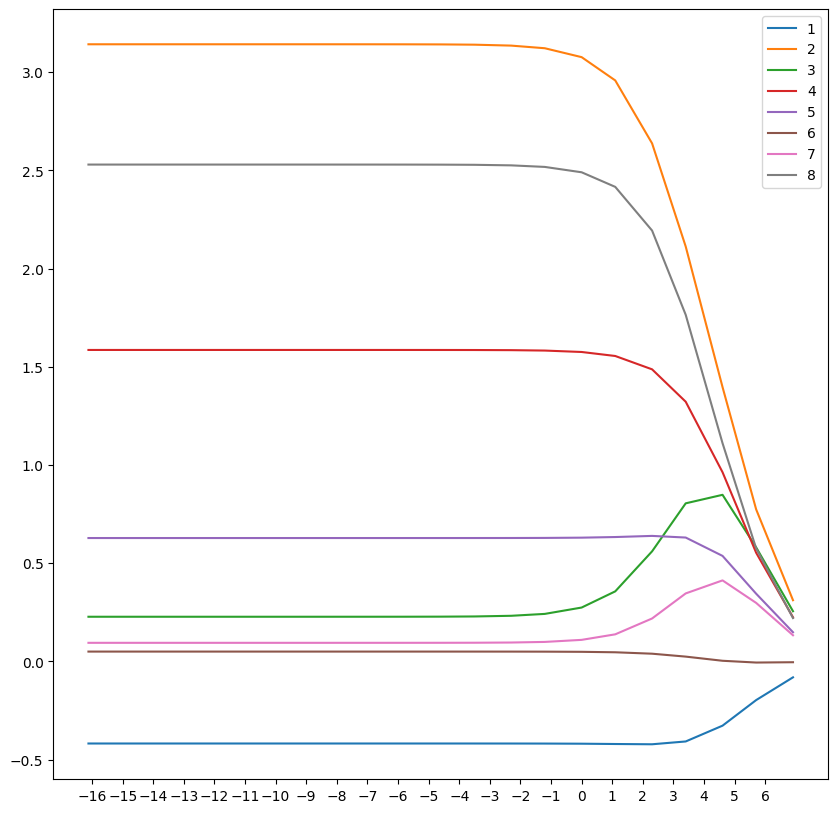

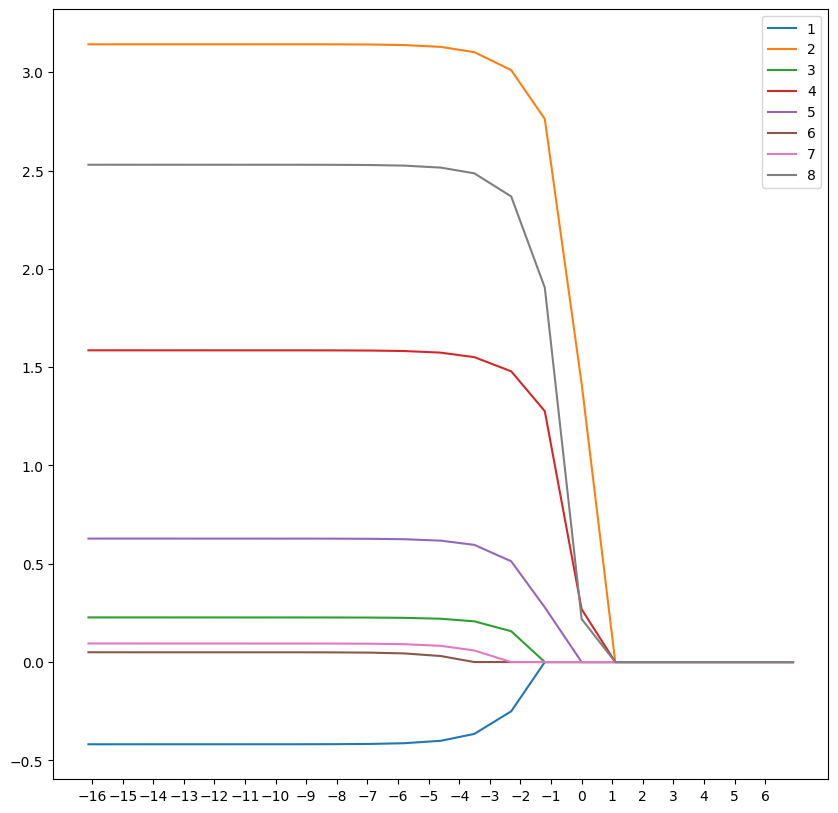

In [ ]:
alphas = [1e-7, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1, 3, 10, 30, 100, 300, 1000]
log_al=np.log(np.array(alphas))
reg=linear_model.LinearRegression()
reg.fit(X_train_clean,y_train_clean)
print(reg.coef_)

features=reg.coef_.size
print(features)
coeffs=[]
for i in alphas:
    ridge=linear_model.Ridge(alpha=i)
    ridge.fit(X_train_clean,y_train_clean)
    coeffs.append(ridge.coef_)

coeffs=np.array(coeffs)

plt.figure(figsize=(10,10))
for i in range(features):
    plt.plot(log_al,coeffs[:,i],label=i+1)
plt.xticks(np.arange(int(log_al.min()), int(log_al.max()) + 1))
plt.legend()
plt.show()

coeffs=[]
for i in alphas:
    lasso=linear_model.Lasso(alpha=i)
    lasso.fit(X_train_clean,y_train_clean)
    coeffs.append(lasso.coef_)

coeffs=np.array(coeffs)

plt.figure(figsize=(10,10))
for i in range(features):
    plt.plot(log_al,coeffs[:,i],label=i+1)
plt.xticks(np.arange(int(log_al.min()), int(log_al.max()) + 1))
plt.legend()
plt.show()


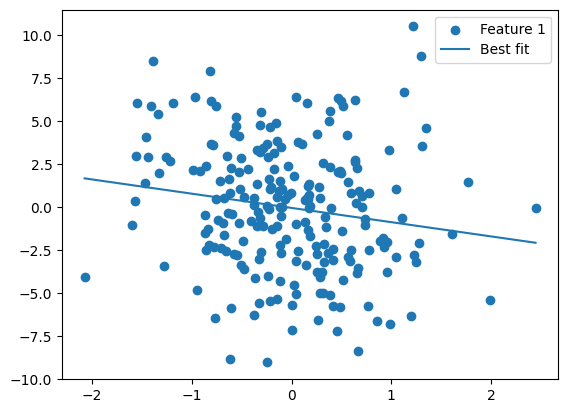

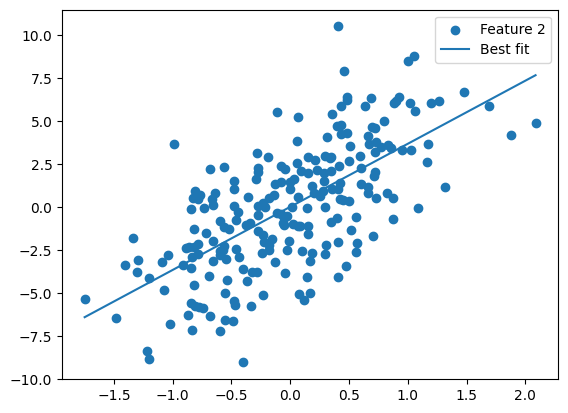

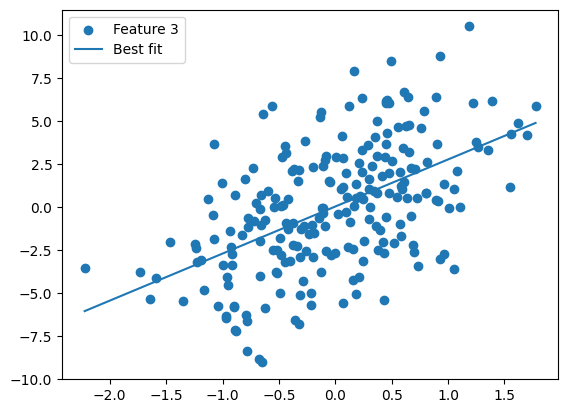

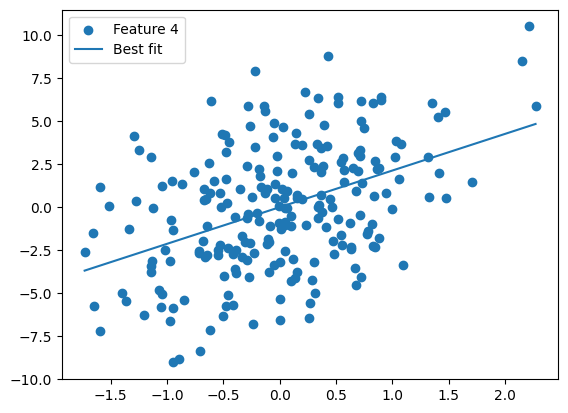

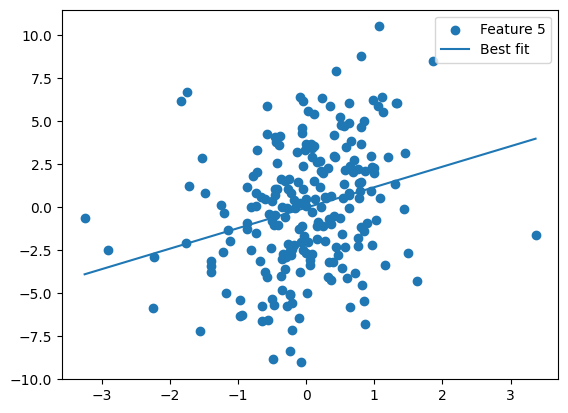

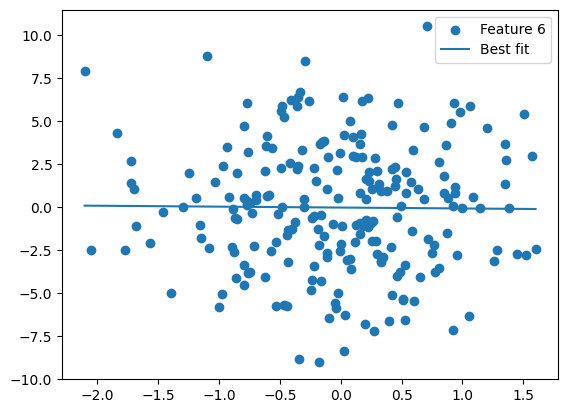

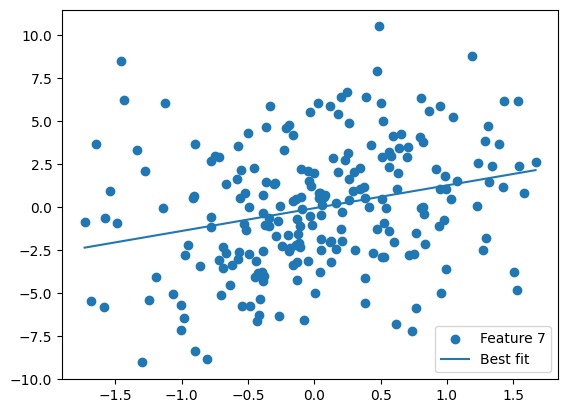

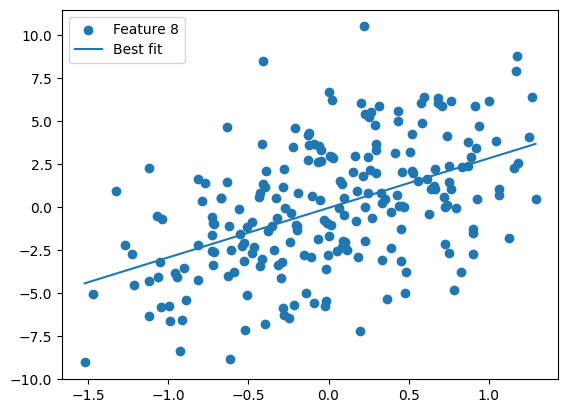

In [ ]:
for i in range(X_train_clean.shape[1]):
    x = X_train_clean[:, i]
    plt.figure()
    plt.scatter(x, y_train_clean, label=f'Feature {i+1}')
    plt.plot(np.sort(x), np.polyval(np.polyfit(x, y_train_clean, 1), np.sort(x)), label='Best fit')
    plt.legend()
    plt.show()

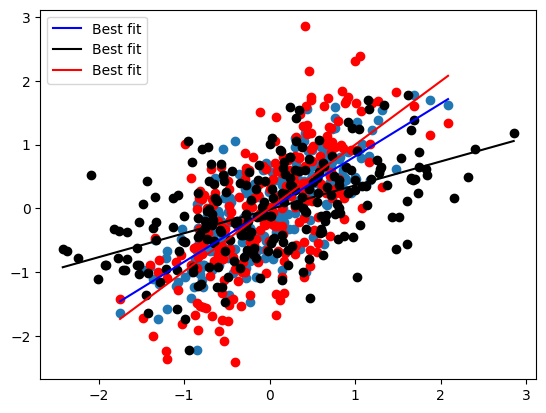

In [ ]:
x1 = std_X_train[:, 1]
x2 = std_X_train[:, 2]
std_y_train = (y_train - np.mean(y_train)) / np.std(y_train)
plt.figure()
plt.scatter(x1, x2)
plt.scatter(x1, std_y_train, color="red")
plt.scatter(std_y_train,x2, color="black")
plt.plot(np.sort(x1), np.polyval(np.polyfit(x1, x2, 1), np.sort(x1)), label='Best fit', color="blue")
plt.plot(np.sort(std_y_train), np.polyval(np.polyfit(std_y_train, x2, 1), np.sort(std_y_train)), label='Best fit', color="black")
plt.plot(np.sort(x1), np.polyval(np.polyfit(x1, std_y_train, 1), np.sort(x1)), label='Best fit', color="red")
plt.legend()
plt.show()

# Final

In [ ]:
def train_and_write_csv(X_train, y_train, test_csv, feature_indices, output_csv="predictions.csv"):
    test = np.loadtxt(test_csv, skiprows=1, delimiter=",")
    test_ids = test[:, 0]
    X_test = test[:, 1:]
    X_train_sel = X_train[:, feature_indices]
    X_test_sel = std_X_test[:, feature_indices]
    model = sklearn.linear_model.Ridge(alpha=0)
    model.fit(X_train_sel, y_train)

    y_pred = model.predict(X_test_sel)

    output = np.column_stack((test_ids.astype(int), y_pred))
    np.savetxt(output_csv,output,delimiter=",",header="Id,y",comments="")

    print(f"Saved predictions to {output_csv}")

train_and_write_csv(std_X_train, y_train, "q5_test.csv",[0, 1, 3, 4, 6],"q5_predictions.csv") #3,6,8

Saved predictions to q5_predictions.csv


# Replace blue with red selectively (x1 with x2)

Variance from line (x1): 0.6866719187458814
Variance from line (x2): 0.6633474805736245


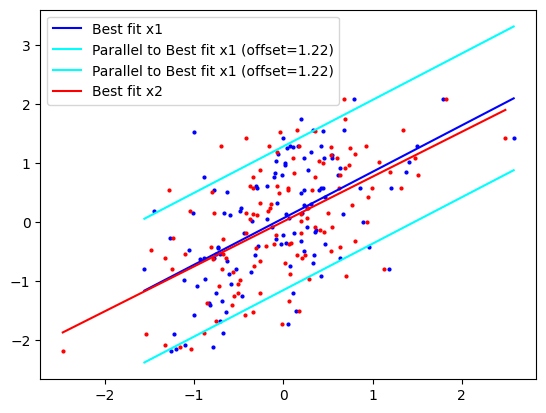

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x1 = std_X_train[:, 1]
x2 = std_X_train[:, 2]

std_y_train = (y_train - np.mean(y_train)) / np.std(y_train)

# Fit lines
coef1 = np.polyfit(x1, std_y_train, 1)
coef2 = np.polyfit(x2, std_y_train, 1)

yhat1 = np.polyval(coef1, x1)
yhat2 = np.polyval(coef2, x2)

# Residuals
res1 = std_y_train - yhat1
res2 = std_y_train - yhat2

# Variance of residuals
var1 = np.var(res1)
var2 = np.var(res2)

print("Variance from line (x1):", var1)
print("Variance from line (x2):", var2)

# Define an offset for the parallel line
perpendicular_offset = 1.22 # You can change this value to adjust the distance

# Plot
plt.figure()
plt.scatter(x1, std_y_train, s=4, color="blue")
plt.scatter(x2, std_y_train, s=4, color="red")

plt.plot(
    np.sort(x1),
    np.polyval(coef1, np.sort(x1)),
    color="blue", label="Best fit x1"
)

# Plot the new parallel line
plt.plot(
    np.sort(x1),
    np.polyval(coef1, np.sort(x1)) + perpendicular_offset, # Add the offset here
    color="cyan", label=f"Parallel to Best fit x1 (offset={perpendicular_offset})"
)
plt.plot(
    np.sort(x1),
    np.polyval(coef1, np.sort(x1)) - perpendicular_offset, # Add the offset here
    color="cyan", label=f"Parallel to Best fit x1 (offset={perpendicular_offset})"
)

plt.plot(
    np.sort(x2),
    np.polyval(coef2, np.sort(x2)),
    color="red", label="Best fit x2"
)

plt.legend()
plt.show()

# Task
Calculate the upper and lower bounds of the cyan parallel lines, then identify the indices where the `std_y_train` values (y-values) fall outside these bounds when associated with `x1`. Create a new array `x1_modified` by copying `x1` and replacing the values at the identified outlier indices with the corresponding `x2` values. Finally, plot `x1_modified` against `std_y_train` to visualize the effect of the replacements, including the original best-fit lines for `x1` and `x2`, and the cyan parallel lines, with an appropriate legend.

## Identify Outliers and Replace

### Subtask:
Calculate the upper and lower bounds of the cyan lines. Identify the indices where `std_y_train` (the y-values) falls outside these bounds when considering `x1`. Create a copy of `x1` and replace the `x1` values at these identified indices with the corresponding `x2` values.


**Reasoning**:
First, calculate the upper and lower bounds of the cyan lines based on `coef1`, `x1`, and `perpendicular_offset`. Then, identify the indices where `std_y_train` falls outside these bounds. Finally, create a modified copy of `x1` where the identified outlier values are replaced with corresponding values from `x2`.



In [ ]:
upper_bound = np.polyval(coef1, x1) + perpendicular_offset
lower_bound = np.polyval(coef1, x1) - perpendicular_offset

outlier_indices = np.where((std_y_train > upper_bound) | (std_y_train < lower_bound))

x1_modified = x1.copy()
x1_modified[outlier_indices] = x2[outlier_indices]

print(f"Number of outliers identified: {len(outlier_indices[0])}")
print("First 5 elements of x1_modified:")
print(x1_modified[:5])
print("First 5 elements of original x1:")
print(x1[:5])

Number of outliers identified: 18
First 5 elements of x1_modified:
[ 0.42615289 -0.77063187  0.85672189 -1.11723633  0.28245108]
First 5 elements of original x1:
[ 0.42615289 -0.77063187  0.85672189 -1.11723633  0.28245108]


In [ ]:
variance_x1_modified = np.var(x1_modified)
print(f"Variance of x1_modified: {variance_x1_modified}")

Variance of x1_modified: 0.5312864449901508


**Reasoning**:
The next step is to visualize the effect of the outlier replacement by plotting `x1_modified` against `std_y_train`, including the original best-fit lines and the cyan parallel lines, as requested in the main task.



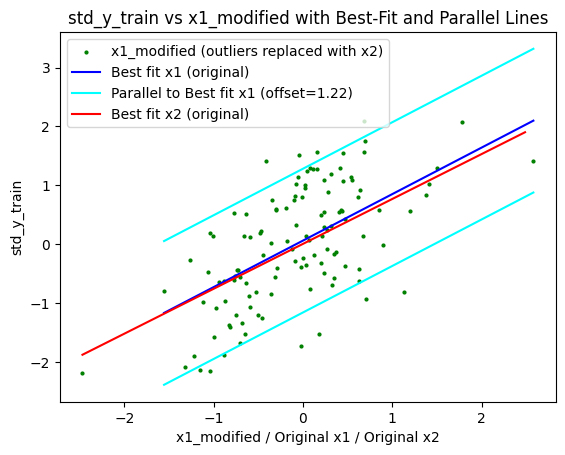

In [ ]:
plt.figure()
plt.scatter(x1_modified, std_y_train, s=4, color="green", label="x1_modified (outliers replaced with x2)")

plt.plot(
    np.sort(x1),
    np.polyval(coef1, np.sort(x1)),
    color="blue", label="Best fit x1 (original)"
)

plt.plot(
    np.sort(x1),
    np.polyval(coef1, np.sort(x1)) + perpendicular_offset,
    color="cyan", label=f"Parallel to Best fit x1 (offset={perpendicular_offset})"
)
plt.plot(
    np.sort(x1),
    np.polyval(coef1, np.sort(x1)) - perpendicular_offset,
    color="cyan"
)

plt.plot(
    np.sort(x2),
    np.polyval(coef2, np.sort(x2)),
    color="red", label="Best fit x2 (original)"
)

plt.title("std_y_train vs x1_modified with Best-Fit and Parallel Lines")
plt.xlabel("x1_modified / Original x1 / Original x2")
plt.ylabel("std_y_train")
plt.legend()
plt.show()

# Task
Identify indices where data points are both outliers with respect to `x1` (i.e., outside the cyan parallel lines) and for which `x2` provides a better fit (i.e., has a smaller absolute residual) than `x1`. Then, create a new `x1_modified` array by replacing the `x1` values at these specific indices with the corresponding `x2` values. Finally, plot `x1_modified` against `std_y_train` along with the best-fit lines for `x1` and `x2` and the cyan parallel lines to visualize the conditional replacements.

## Identify Conditional Replacement Indices

### Subtask:
Calculate the upper and lower bounds of the cyan lines. Identify the indices where `std_y_train` falls outside these bounds when considering `x1`. Then, calculate the absolute residuals for both `x1` and `x2` against `std_y_train`. Finally, identify a new set of indices where a data point is both an outlier with respect to `x1` (based on the cyan lines) AND `x2` provides a better fit (i.e., has a smaller absolute residual) than `x1`.


**Reasoning**:
The subtask requires calculating the absolute residuals for `x1` and `x2`, then identifying specific indices where `std_y_train` is an outlier relative to `x1` AND `x2` provides a better fit than `x1` based on absolute residuals. This can be achieved with `numpy` operations.



In [ ]:
abs_res1 = np.abs(res1)
abs_res2 = np.abs(res2)

outlier_x1 = (std_y_train > upper_bound) | (std_y_train < lower_bound)
better_fit_x2 = (abs_res2 < abs_res1)

conditional_replacement_indices = np.where(outlier_x1 & better_fit_x2)

print(f"Number of conditional replacement indices identified: {len(conditional_replacement_indices[0])}")

Number of conditional replacement indices identified: 13


**Reasoning**:
Now that the `conditional_replacement_indices` have been identified, the next step is to create `x1_modified` by replacing the `x1` values at these indices with the corresponding `x2` values, as specified in the subtask.



In [ ]:
x1_modified = x1.copy()
x1_modified[conditional_replacement_indices] = x2[conditional_replacement_indices]

print(f"Number of values replaced in x1_modified: {len(conditional_replacement_indices[0])}")
print("First 5 elements of x1_modified after conditional replacement:")
print(x1_modified[:5])

Number of values replaced in x1_modified: 13
First 5 elements of x1_modified after conditional replacement:
[ 0.42615289 -0.77063187  0.85672189 -1.11723633  0.28245108]


**Reasoning**:
Now that `x1_modified` has been updated with conditional replacements, the next step is to visualize the effect by plotting `x1_modified` against `std_y_train`, along with the original best-fit lines and the cyan parallel lines, as requested in the main task.



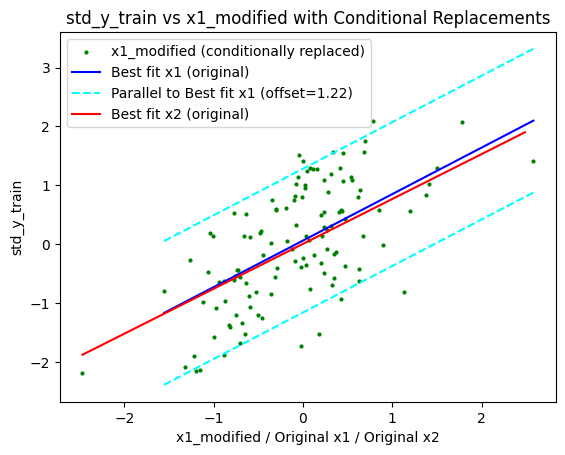

In [ ]:
plt.figure()
plt.scatter(x1_modified, std_y_train, s=4, color="green", label="x1_modified (conditionally replaced)")

plt.plot(
    np.sort(x1),
    np.polyval(coef1, np.sort(x1)),
    color="blue", label="Best fit x1 (original)"
)

plt.plot(
    np.sort(x1),
    np.polyval(coef1, np.sort(x1)) + perpendicular_offset,
    color="cyan", label=f"Parallel to Best fit x1 (offset={perpendicular_offset})", linestyle='--'
)
plt.plot(
    np.sort(x1),
    np.polyval(coef1, np.sort(x1)) - perpendicular_offset,
    color="cyan", linestyle='--'
)

plt.plot(
    np.sort(x2),
    np.polyval(coef2, np.sort(x2)),
    color="red", label="Best fit x2 (original)"
)

plt.title("std_y_train vs x1_modified with Conditional Replacements")
plt.xlabel("x1_modified / Original x1 / Original x2")
plt.ylabel("std_y_train")
plt.legend()
plt.show()

In [ ]:
variance_x1_modified = np.var(x1_modified)
print(f"Variance of x1_modified: {variance_x1_modified}")

Variance of x1_modified: 0.5312864449901508


In [ ]:
std_X_train_modified=std_X_train
std_X_train_modified[:,1]=x1_modified
def train_and_write_csv(X_train, y_train, test_csv, feature_indices, output_csv="predictions.csv"):
    test = np.loadtxt(test_csv, skiprows=1, delimiter=",")
    test_ids = test[:, 0]
    X_test = test[:, 1:]
    X_train_sel = X_train[:, feature_indices]
    X_test_sel = std_X_test[:, feature_indices]
    model = sklearn.linear_model.Ridge(alpha=0)
    model.fit(X_train_sel, y_train)

    y_pred = model.predict(X_test_sel)

    output = np.column_stack((test_ids.astype(int), y_pred))
    np.savetxt(output_csv,output,delimiter=",",header="Id,y",comments="")

    print(f"Saved predictions to {output_csv}")

train_and_write_csv(std_X_train, y_train, "q5_test.csv",[0, 1, 3, 4, 6],"q5_predictions.csv") #3,6,8

Saved predictions to q5_predictions.csv
